# Experiment 1: Hardware True Random Number Generator on the PYNQ-Z2

Four ring oscillators on the FPGA produce random bits from their timing jitter.
The sampler XORs the samples over a window of `2**k` clock cycles and a Von Neumann
filter removes the bias. This notebook reads the bits over AXI, plots them, and runs
two NIST randomness tests.

Registers: `0x00` enable, `0x04` status, `0x08` data, `0x0C` window `k`.

The raw bits are not a cryptographic key on their own; hash them before any such use.

In [2]:
%matplotlib inline
from pynq import Overlay, MMIO
import numpy as np
import matplotlib.pyplot as plt
import time
import math
import hashlib

REG_CTRL, REG_STATUS, REG_DATA, REG_WINDOW = 0x00, 0x04, 0x08, 0x0C

overlay = Overlay('system_wrapper.bit')
ip = overlay.ip_dict.get('trng_top_0/s_axi') or overlay.ip_dict['trng_top_0']
trng = MMIO(ip['phys_addr'], 0x1000)
print(f"Overlay loaded, TRNG at 0x{ip['phys_addr']:08X}")


Read 100000 bytes in 2.0 s with window k = 6


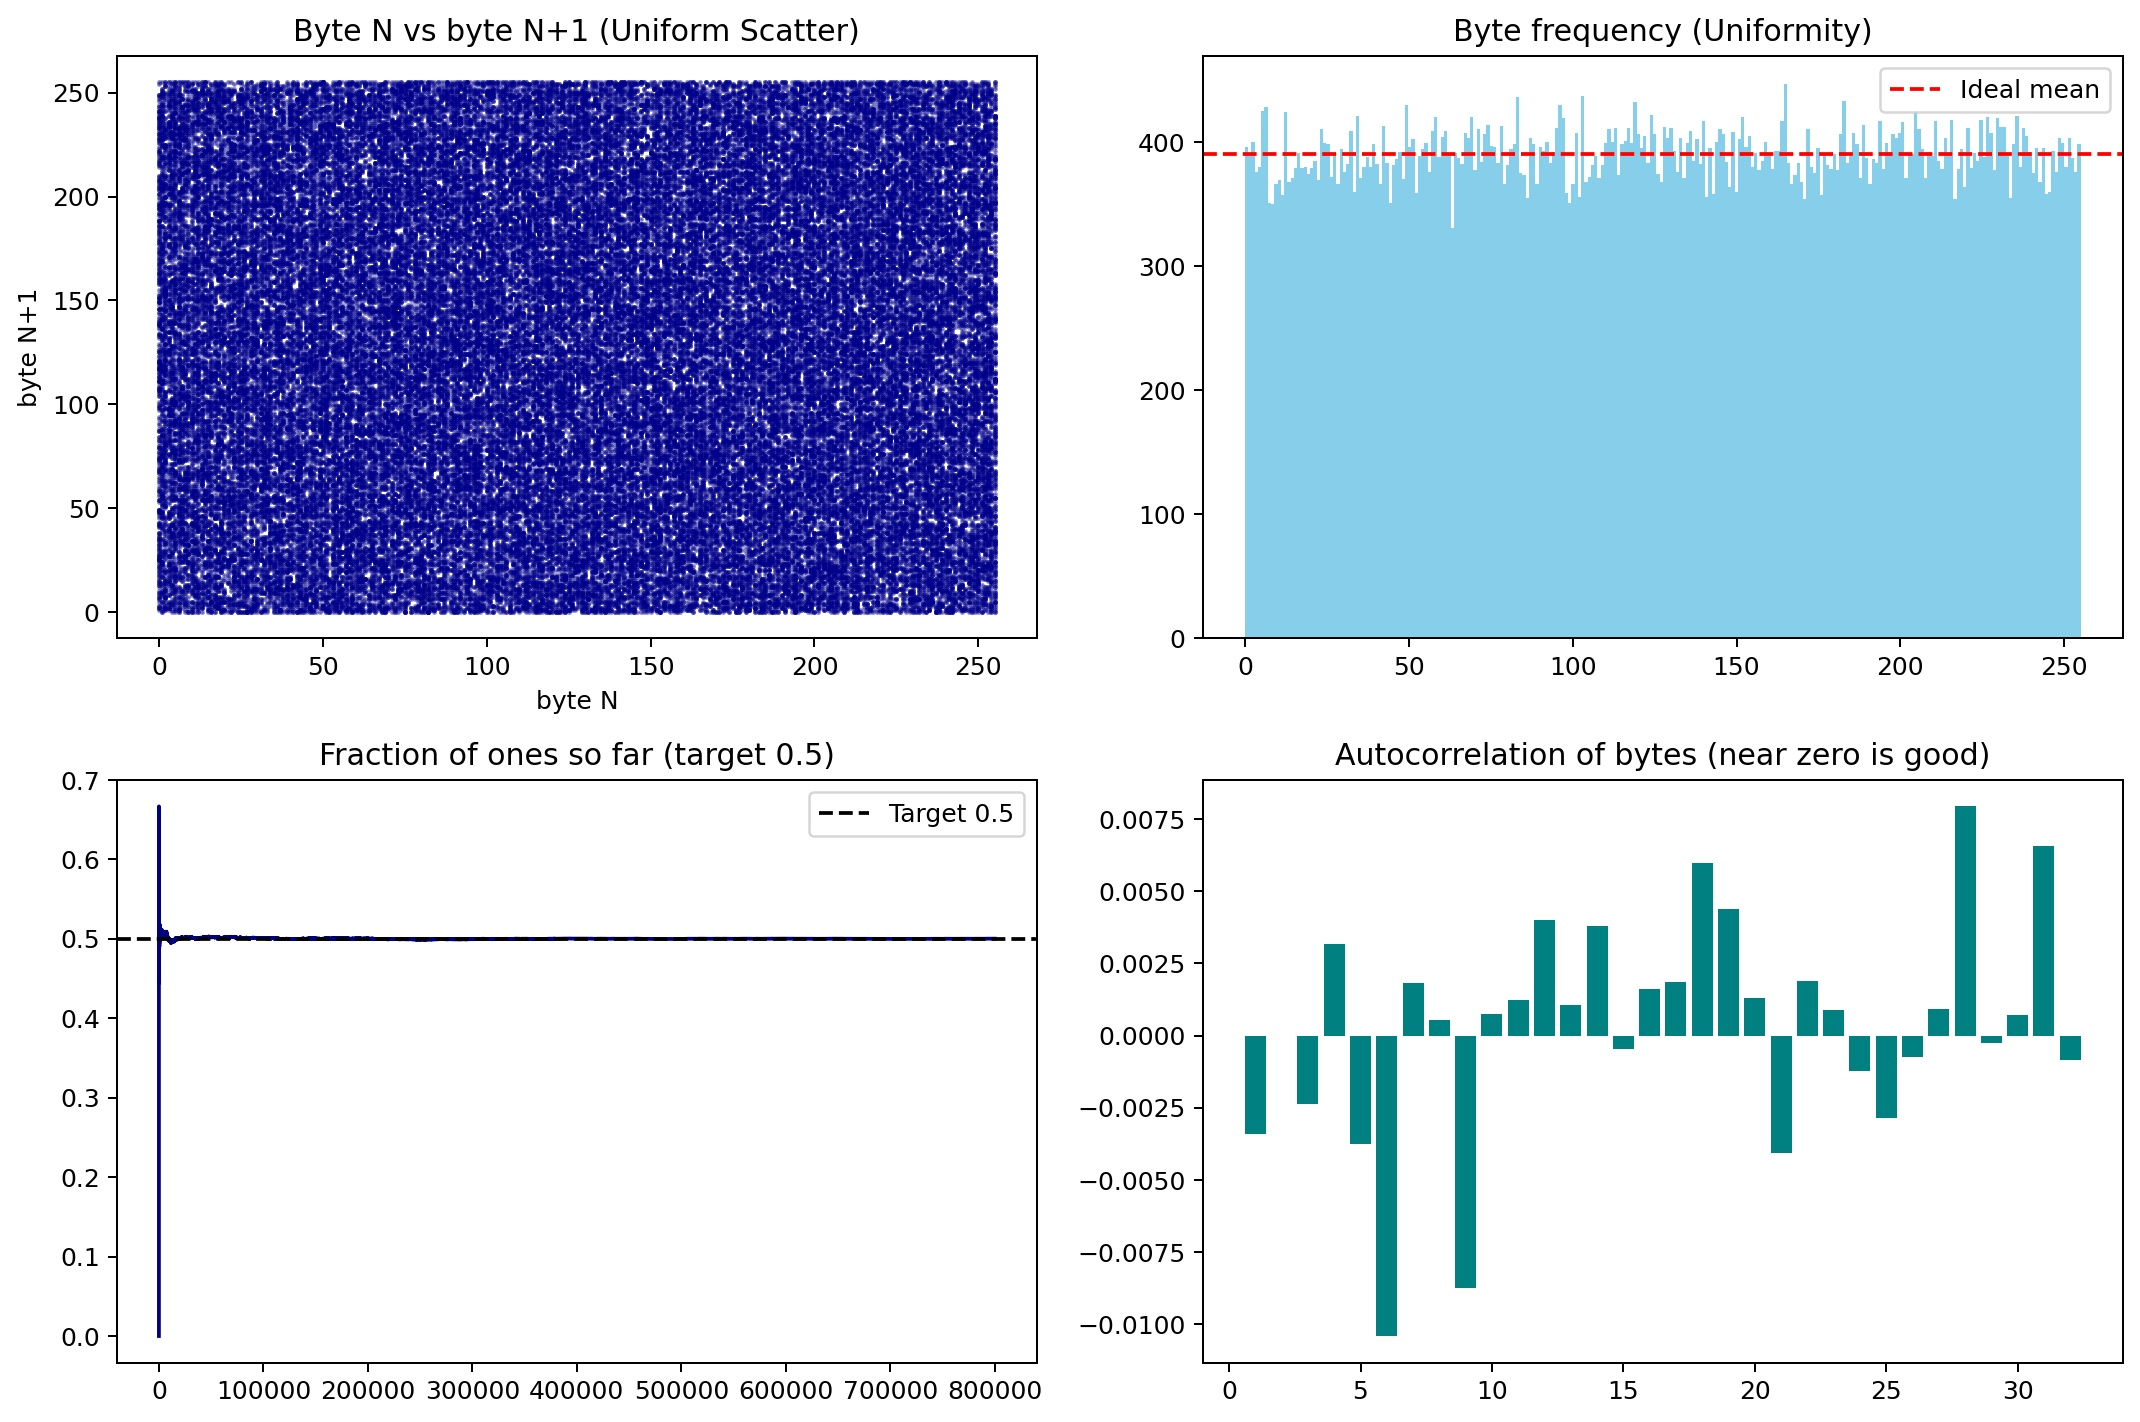

In [3]:
WINDOW_K = 6                                                

trng.write(REG_WINDOW, WINDOW_K)
if trng.read(REG_WINDOW) != WINDOW_K:
    raise RuntimeError('Window register did not accept the value - is the latest bitstream loaded?')
trng.write(REG_CTRL, 1)                           
time.sleep(0.01)

def read_bytes(n):

    data = bytearray()
    while len(data) < n:
        if trng.read(REG_STATUS) & 1:                                     
            time.sleep(0.001)
            continue
        data += trng.read(REG_DATA).to_bytes(4, 'little')
    return np.frombuffer(bytes(data[:n]), dtype=np.uint8)

start = time.time()
data = read_bytes(100000)
bits = np.unpackbits(data)
print(f'Read {len(data)} bytes in {time.time() - start:.1f} s with window k = {WINDOW_K}')


In [4]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

axs[0, 0].scatter(data[:-1], data[1:], s=1, alpha=0.4)
axs[0, 0].set_title('Byte N vs byte N+1 (no pattern expected)')
axs[0, 0].set_xlabel('byte N')
axs[0, 0].set_ylabel('byte N+1')

axs[0, 1].hist(data, bins=256)
axs[0, 1].axhline(len(data) / 256, color='red', linestyle='--')
axs[0, 1].set_title('Byte frequency (flat is good)')

axs[1, 0].plot(np.cumsum(bits) / np.arange(1, len(bits) + 1))
axs[1, 0].axhline(0.5, color='black', linestyle='--')
axs[1, 0].set_title('Fraction of ones so far (target 0.5)')

centred = data.astype(float) - data.mean()
lags = range(1, 33)
axs[1, 1].bar(list(lags), [np.sum(centred[:-k] * centred[k:]) / np.sum(centred * centred) for k in lags])
axs[1, 1].set_title('Autocorrelation of bytes (near zero is good)')

plt.tight_layout()
plt.show()


Ones:           50.02 %
Entropy:        7.9982 / 8.0 bits per byte
Longest run:    17 identical bits
NIST frequency: PASS (p = 0.7628)
NIST runs:      PASS (p = 0.5506)
SHA-256 of the 100,000 bytes: 84aff8366f9fb517edf6d34706c0e748c579ebaee232a52a68a3b44718302f30


In [ ]:
n = len(bits)
ones = int(np.sum(bits))
fraction_ones = ones / n


s_obs = abs(2 * ones - n) / math.sqrt(n)
freq_p = math.erfc(s_obs / math.sqrt(2))


changes = int(np.sum(bits[:-1] != bits[1:]))
expected = 2 * n * fraction_ones * (1 - fraction_ones)
runs_p = math.erfc(abs(changes + 1 - expected) / (2 * math.sqrt(2 * n) * fraction_ones * (1 - fraction_ones)))


counts = np.bincount(data, minlength=256)
probabilities = counts[counts > 0] / len(data)
entropy = -np.sum(probabilities * np.log2(probabilities))


edges = np.concatenate(([-1], np.flatnonzero(bits[:-1] != bits[1:]), [n - 1]))
longest_run = int(np.max(np.diff(edges)))

print(f'Ones:           {100 * fraction_ones:.2f} %')
print(f'Entropy:        {entropy:.4f} / 8.0 bits per byte')
print(f'Longest run:    {longest_run} identical bits')
print(f'NIST frequency: {"PASS" if freq_p > 0.01 else "FAIL"} (p = {freq_p:.4f})')
print(f'NIST runs:      {"PASS" if runs_p > 0.01 else "FAIL"} (p = {runs_p:.4f})')
if freq_p <= 0.01 or runs_p <= 0.01:
    print('Tip: raise WINDOW_K by 2 in the cell above and run again.')

print(f'\nSHA-256 of the 100,000 bytes: {hashlib.sha256(data.tobytes()).hexdigest()}')
